# Approximate values against an exact Bellman reference

Family 36. RL is optional. The finite reference exposes Bellman error directly. A small training residual is evidence about this supplied simulator, not predictive quality or profitability.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'convexity').exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize': (9, 3.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})
print('Interpreter:', sys.executable)

Interpreter: /home/ethan/miniconda3/envs/quant/bin/python


## Public workflow

The executable example uses only supplied or generated inputs.

In [2]:
"""Family 36: exact control versus sampled and approximated value learning.

The base example needs no optional tensor libraries. Install [reinforcement]
and pass --neural to train the Stable-Baselines3 actor-critic backend too.
"""
import sys
import numpy as np
from convexity.math import control, reinforcement

mdp = control.FiniteMDP([[[1.], [1.]]], [[0., 1.]], .5)
exact = control.value_iteration(mdp)
sampled = reinforcement.q_learning(mdp, steps=30000, epsilon=.4, rng=np.random.default_rng(3600))
fitted = reinforcement.fitted_q(mdp, np.eye(2).reshape(1, 2, 2))
print('Exact value:', exact.values, 'sampled Q:', sampled.q_values, 'fitted Q:', fitted.q_values)
print('Bellman residuals:', sampled.residual, fitted.residual)
if '--neural' in sys.argv:
    agent = reinforcement.train_agent(mdp, steps=512, seed=11, learning_rate=.01)
    print('Actor-critic action:', agent.action(0))


Exact value: [2.] sampled Q: [[1. 2.]] fitted Q: [[1. 2.]]
Bellman residuals: 1.4210854715202004e-14 4.656612873077393e-10


## Sample budgets and an actor-critic adapter

One-hot fitted Q recovers the finite reference. Sampled Q learning approaches it as transitions accumulate. The optional actor-critic run below uses a real Stable-Baselines3 backend on the same simple model.

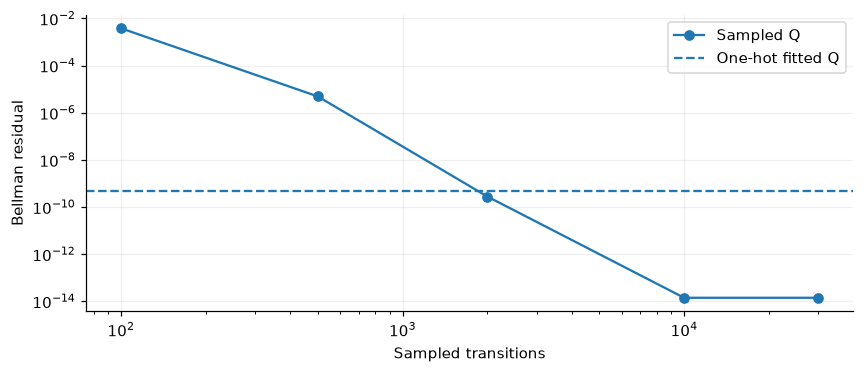

Actor-critic action: 1 exact action: 1


In [3]:
budgets = [100, 500, 2000, 10000, 30000]
residuals = [reinforcement.q_learning(mdp, steps=n, epsilon=.4, rng=np.random.default_rng(3600)).residual for n in budgets]
plt.loglog(budgets, np.maximum(residuals, 1e-16), marker='o', label='Sampled Q')
plt.axhline(fitted.residual, linestyle='--', label='One-hot fitted Q')
plt.xlabel('Sampled transitions'); plt.ylabel('Bellman residual'); plt.legend(); plt.show()
agent = reinforcement.train_agent(mdp, steps=512, seed=11, learning_rate=.01)
print('Actor-critic action:', agent.action(0), 'exact action:', exact.policy[0])

## Scope of this evidence

These experiments illustrate the declared finite catalog, not live trading performance. See the [contracts and limitations](../decision_mathematics.md) and `tests/math/decisions/` for mathematical acceptance checks.